# Power-network disruption: does local position help predict later interruptions?

Choose **this option or the hospital option**, not both. This small synthetic dataset describes a grid-like network of substations. One substation is already interrupted at the prediction point. Predict which of the **other** substations experiences a simulated interruption during the following 24 hours. The data are not a physical cascade simulation.

Work through Part 1 (data and EDA), Part 2 (network), and Part 3 (comparison). Most code is provided. Replace six obvious `___` markers using the hints beside them, then complete the short written responses. Keep code, plots and short answers visible when you submit the notebook. Do not use `interrupted_later` to construct predictors.


> **Solution notes (Claude).** This is my completed version of the guided notebook, for comparison with your own. The six `___` markers are filled in and the written answers are mine. Cells marked "Extra" are my additions and are not required by the brief. The two CSV files were downloaded from the course URL when this was run; copies are saved beside this notebook for offline work.

## Portfolio summary

**Question.** For substations still functioning after one initial interruption, does position in the physical network help predict a simulated interruption during the next 24 hours, beyond load ratio and equipment age?

**Approach.** I built an undirected network of 144 substations and 344 physical links, and calculated each substation's degree and local clustering coefficient. I then compared two logistic regressions on the same stratified 70/30 split of the 143 eligible substations, with scaling fitted on training rows only.

**Principal result.** On the 43 test substations the network features raised F1 from 0.444 to 0.750 and ROC AUC from 0.828 to 0.949, and cut missed interruptions from 8 to 3 of 12, at the cost of one extra false alarm.

**Main limitation.** The data are synthetic and this split is favourable: over 200 other splits the average ROC AUC gain was only 0.744 to 0.786. No cascade is simulated, so the result does not show propagation, cause, or suitability for operating a real grid.


## Part 1: load the prepared data and explore it

The two CSVs have already been constructed. The notebook downloads them from published course URLs; if needed, put both provided CSVs beside this notebook. The topology, `load_ratio`, `equipment_age_years`, and the initial status are available at prediction time. The later outcome is blank for the already interrupted substation.


In [1]:
DATA_BASE_URL = 'https://raw.githubusercontent.com/mikeauth/leap/main/power'
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

SEED = 123

def load_course_csv(filename):
    # The course address is the folder containing the prepared CSVs. For offline work, keep a
    # downloaded CSV in the same folder as this notebook.
    url = f'{DATA_BASE_URL}/{filename}'
    try:
        return pd.read_csv(url)
    except Exception:
        local = Path(filename)
        if local.is_file():
            print(f'Using local copy of {filename}; course URL was unavailable.')
            return pd.read_csv(local)
        raise FileNotFoundError(f'Cannot read {url}. Download {filename} next to the notebook or ask for the course URL.')

substations = load_course_csv('power_substations.csv')
links = load_course_csv('power_links.csv')
assert substations['substation_id'].is_unique
assert {'substation_id','load_ratio','equipment_age_years','initially_interrupted','interrupted_later'} <= set(substations)
assert {'substation_a','substation_b'} <= set(links)
display(substations.head())
display(links.head())
print('Substations:',len(substations),'Links:',len(links))


,substation_id,load_ratio,equipment_age_years,initially_interrupted,interrupted_later
0,S001,0.506,24,0,0.0
1,S002,0.708,17,0,0.0
2,S003,0.555,13,0,0.0
3,S004,0.883,36,0,1.0
4,S005,0.643,35,0,0.0


,substation_a,substation_b
0,S001,S002
1,S001,S013
2,S002,S003
3,S002,S014
4,S003,S004


Substations: 144 Links: 344


### Focused EDA: follow the worked code

Exclude the initially interrupted substation. Count eligible substations and later classes. Show one bar chart of later interruptions and two boxplots comparing `load_ratio` and `equipment_age_years` by later outcome. Note any overlap between classes.


Eligible: 143 Later interruptions: 39


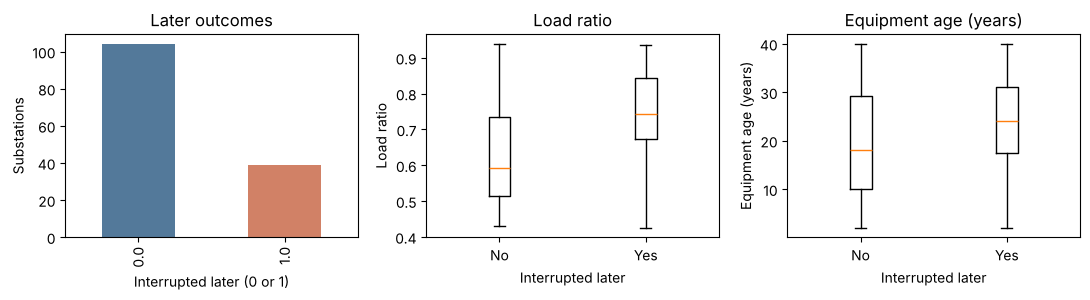

In [2]:
# TODO 1: Select substations functioning at the start.
# Hint: substations['initially_interrupted'].eq(0)
eligible_eda=substations.loc[substations['initially_interrupted'].eq(0)].copy()
assert eligible_eda['interrupted_later'].notna().all()
counts=eligible_eda['interrupted_later'].value_counts().reindex([0.,1.],fill_value=0)
print('Eligible:',len(eligible_eda),'Later interruptions:',int(counts.loc[1.]))
fig,axes=plt.subplots(1,3,figsize=(11,3.1))
counts.plot.bar(ax=axes[0],color=['#53799a','#d18166'])
axes[0].set(xlabel='Interrupted later (0 or 1)',ylabel='Substations',title='Later outcomes')
for ax,column,label in zip(axes[1:],['load_ratio','equipment_age_years'],['Load ratio','Equipment age (years)']):
    groups=[eligible_eda.loc[eligible_eda['interrupted_later'].eq(k),column] for k in [0,1]]
    ax.boxplot(groups,tick_labels=['No','Yes'])
    ax.set(xlabel='Interrupted later',ylabel=label,title=label)
plt.tight_layout();plt.show()


In [3]:
# Extra: the medians behind the two boxplots
display(eligible_eda.groupby('interrupted_later')[['load_ratio', 'equipment_age_years']].median().round(3))


,load_ratio,equipment_age_years
interrupted_later,,
0.0,0.591,18.0
1.0,0.742,24.0


**Write here:** How many substations are eligible? What overlap do you see in the two original attributes? (Two or three sentences.)

**Answer.** 143 substations are eligible (all except the initially interrupted S066); 39 of them (27%) are interrupted later and 104 are not. Substations interrupted later tend to carry a higher load (median 0.74 against 0.59) and to be older (median 24 against 18 years), but both classes span almost the whole range of each attribute. The overlap is large, particularly for equipment age, so these two attributes alone cannot separate the classes cleanly.


## Part 2: undirected physical-link network

Each `power_links.csv` row gives one physical link with no direction or weight. Add every substation as a node. Calculate degree (number of direct links) and local clustering coefficient (what proportion of possible links **among direct neighbours** exists). The few extra local cross-links make clustering vary. Neither feature uses later interruptions.


In [4]:
G=nx.Graph()
G.add_nodes_from(substations['substation_id'])
valid=set(substations['substation_id'])
assert links['substation_a'].isin(valid).all() and links['substation_b'].isin(valid).all()
assert (links['substation_a']!=links['substation_b']).all()
for row in links.itertuples(index=False):
    # TODO 2: Complete the second endpoint of the physical link.
    # Hint: G.add_edge(row.substation_a, row.substation_b)
    G.add_edge(row.substation_a, row.substation_b)
assert G.number_of_edges()==len(links)
substations['degree']=[G.degree(i) for i in substations['substation_id']]
# TODO 3: Supply the graph to calculate local clustering.
# Hint: clustering = nx.clustering(G)
clustering=nx.clustering(G)
substations['local_clustering']=[clustering[i] for i in substations['substation_id']]
print('Nodes:',G.number_of_nodes(),'Links:',G.number_of_edges())
print('Degree range:',substations['degree'].min(),substations['degree'].max())
display(substations[['substation_id','degree','local_clustering']].head())


Nodes: 144 Links: 344
Degree range: 2 8


,substation_id,degree,local_clustering
0,S001,2,0.000000
1,S002,3,0.000000
2,S003,4,0.333333
3,S004,4,0.500000
4,S005,3,0.333333


### Visualise and interpret the network

Draw the small network, colouring the initially interrupted node differently from the others, and make one plot comparing the distribution of degree and clustering coefficient. The visualisation uses the **initial** status only. Explain in plain language what a high local clustering value means. The plot is an illustration, not a new model feature.


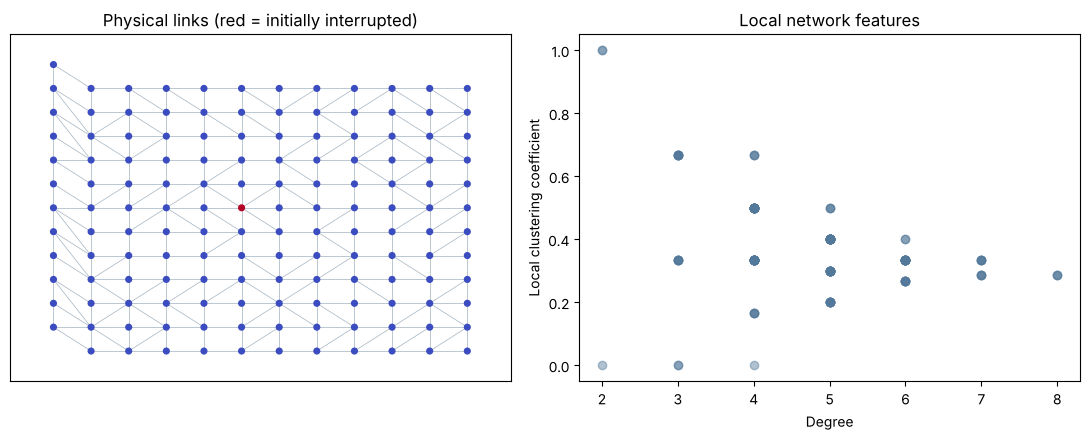

In [5]:
initial=substations.set_index('substation_id')['initially_interrupted']
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
# The numbered IDs encode the synthetic grid's display positions; positions are not predictors.
pos={f'S{i+1:03d}':(i%12,-i//12) for i in range(144)}
nx.draw_networkx(G,pos,ax=axes[0],with_labels=False,node_size=17,
    node_color=[initial.loc[i] for i in G.nodes],cmap='coolwarm',vmin=0,vmax=1,
    edge_color='#aab9c5',width=.55)
axes[0].set_title('Physical links (red = initially interrupted)')
axes[1].scatter(substations['degree'],substations['local_clustering'],alpha=.45,color='#53799a')
axes[1].set(xlabel='Degree',ylabel='Local clustering coefficient',title='Local network features')
plt.tight_layout();plt.show()


In [6]:
# Extra: are degree and local clustering measuring the same thing?
elig = substations.loc[substations['initially_interrupted'].eq(0)]
print('Correlation between degree and local clustering (eligible substations):',
      round(elig['degree'].corr(elig['local_clustering']), 2))
print('Degree counts:', elig['degree'].value_counts().sort_index().to_dict())


Correlation between degree and local clustering (eligible substations): -0.35
Degree counts: {2: 3, 3: 15, 4: 44, 5: 46, 6: 24, 7: 8, 8: 3}


**Write here:** What does it mean for a substation's neighbours to be connected to one another? Why is clustering different from degree? (Two sentences.)

**Answer.** When a substation's neighbours are also linked to one another, its local clustering coefficient is high: the substation sits in a tightly knit neighbourhood with triangles of cross-links around it. Degree only counts how many direct links a substation has, whereas clustering describes how those neighbours are connected among themselves; in this network the two are in fact negatively correlated (the cell above prints the value), because a substation with many links rarely has all of its neighbours interlinked.


## Part 3: compare logistic regression fairly

Only initially functioning substations are eligible. Model A uses `load_ratio` and `equipment_age_years`. Model B adds `degree` and `local_clustering`. Use **exactly the same observations and stratified split** for both. Fit scaling within the training pipeline. Compare accuracy, F1 for later interruptions, ROC AUC from probabilities, and both confusion matrices. Do not infer a physical cascade from any result.


,Accuracy,F1,ROC AUC
Original substation features,0.767,0.444,0.828
Substation + network features,0.860,0.750,0.949


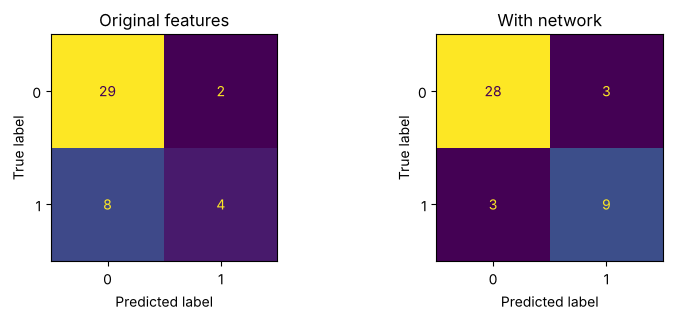

In [7]:
eligible=substations.loc[substations['initially_interrupted'].eq(0)].set_index('substation_id').copy()
y=eligible['interrupted_later'].astype(int)
# TODO 4: Set aside 30% of eligible observations for testing.
# Hint: test_size=.30
train_ids,test_ids=train_test_split(y.index,test_size=.30,stratify=y,random_state=SEED)
original=['load_ratio','equipment_age_years']
# TODO 5: Add the second network feature to the model inputs.
# Hint: with_network = original + ['degree', 'local_clustering']
with_network=original+['degree','local_clustering']

def fit_and_score(columns):
    model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
    model.fit(eligible.loc[train_ids,columns],y.loc[train_ids])
    predicted=model.predict(eligible.loc[test_ids,columns])
    probabilities=model.predict_proba(eligible.loc[test_ids,columns])[:,1]
    scores={'Accuracy':accuracy_score(y.loc[test_ids],predicted),
            'F1':f1_score(y.loc[test_ids],predicted,zero_division=0),
            # TODO 6: Use the predicted probability for ROC AUC.
            # Hint: roc_auc_score(y.loc[test_ids], probabilities)
            'ROC AUC':roc_auc_score(y.loc[test_ids],probabilities)}
    return scores,predicted
base_scores,base_pred=fit_and_score(original)
network_scores,network_pred=fit_and_score(with_network)
results=pd.DataFrame([base_scores,network_scores],index=['Original substation features','Substation + network features'])
display(results.round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.3))
for ax,pred,title in zip(axes,[base_pred,network_pred],['Original features','With network']):
    ConfusionMatrixDisplay.from_predictions(y.loc[test_ids],pred,ax=ax,labels=[0,1],colorbar=False)
    ax.set_title(title)
plt.tight_layout();plt.show()


### Extra checks (beyond the brief)

The brief asks for one stratified split, which is what the table and matrices above report. The two cells below are my own additions: the first prints the matrix counts as numbers, and the second repeats the comparison on 200 other splits to see whether the conclusion depends on the one split used.


In [8]:
# Extra check (not required by the brief): the confusion-matrix counts as numbers
from sklearn.metrics import confusion_matrix
for name, pred in [('Original features', base_pred), ('With network', network_pred)]:
    tn, fp, fn, tp = confusion_matrix(y.loc[test_ids], pred, labels=[0, 1]).ravel()
    print(f'{name:18s} TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print('Test rows:', len(test_ids), '| later events in the test set:', int(y.loc[test_ids].sum()))


Original features  TN=29  FP=2  FN=8  TP=4
With network       TN=28  FP=3  FN=3  TP=9
Test rows: 43 | later events in the test set: 12


In [9]:
# Extra check (not required by the brief): does the result depend on this one split?
# The two models are refitted on 200 different stratified 70/30 splits of the same eligible rows.
from sklearn.model_selection import StratifiedShuffleSplit
rows = []
for tr, te in StratifiedShuffleSplit(n_splits=200, test_size=.30, random_state=0).split(eligible, y):
    row = {}
    for label, cols in [('A', original), ('B', with_network)]:
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        m.fit(eligible.iloc[tr][cols], y.iloc[tr])
        row[f'F1 {label}'] = f1_score(y.iloc[te], m.predict(eligible.iloc[te][cols]), zero_division=0)
        row[f'ROC AUC {label}'] = roc_auc_score(y.iloc[te], m.predict_proba(eligible.iloc[te][cols])[:, 1])
    rows.append(row)
rep = pd.DataFrame(rows)
display(rep.mean().round(3).to_frame('Mean over 200 splits').T)
n_auc = int((rep['ROC AUC B'] > rep['ROC AUC A']).sum())
n_f1 = int((rep['F1 B'] > rep['F1 A']).sum())
print(f'Network model (B) has the higher ROC AUC in {n_auc} of {len(rep)} splits')
print(f'Network model (B) has the higher F1 in      {n_f1} of {len(rep)} splits')


,F1 A,ROC AUC A,F1 B,ROC AUC B
Mean over 200 splits,0.316,0.744,0.466,0.786


Network model (B) has the higher ROC AUC in 168 of 200 splits
Network model (B) has the higher F1 in      172 of 200 splits


**Reading the extra checks.** Across 200 different splits the network model had the higher ROC AUC in 84% of splits and the higher F1 in 86%, but the average gain was modest: mean ROC AUC 0.786 against 0.744, and mean F1 0.466 against 0.316. The direction of the result holds up, but the gain on the single split above (ROC AUC 0.828 to 0.949) is larger than is typical, so I report it as a favourable split and not as the expected size of the improvement.


### Final interpretation and portfolio summary

**Question.** Among substations still functioning, do degree and local clustering add predictive information beyond load ratio and equipment age?

**Answer: yes on this test set, with a caveat.** On the 43 test substations the network model raised F1 from 0.444 to 0.750, ROC AUC from 0.828 to 0.949 and accuracy from 0.767 to 0.860. The baseline missed 8 of the 12 later interruptions and raised 2 false alarms; the network model missed 3 and raised 3. Degree counts a substation's direct links, while local clustering measures how interlinked its neighbours are.

**Caveat.** Across 200 other splits the average gain was much smaller (ROC AUC 0.744 to 0.786), so this split flatters the network model. The interruptions are synthetic and no cascade is simulated, so nothing here shows propagation or cause.

**Ethics.** A false alarm sends crews to sound equipment and delays repairs elsewhere; a missed interruption leaves a community without power. Engineers and the operator should review the priorities.
